### **1.2 Mempelajari Penggunaan Driver Neo4j**

In [1]:
from neo4j import GraphDatabase, RoutingControl

URI = "neo4j://localhost:7687"
AUTH = ("neo4j", "stella1696")


def add_friend(driver, name, friend_name):
    query = (
        "MERGE (a:Person {name: $name}) "
        "MERGE (friend:Person {name: $friend_name}) "
        "MERGE (a)-[:KNOWS]->(friend)"
    )

    driver.execute_query(
        query,
        name=name,
        friend_name=friend_name,
        database_="neo4j",
    )


def print_friends(driver, name):
    query = (
        "MATCH (a:Person)-[:KNOWS]->(friend) WHERE a.name = $name "
        "RETURN friend.name AS friend_name ORDER BY friend_name"
    )

    records, _, _ = driver.execute_query(
        query,
        name=name,
        database_="neo4j",
        routing_=RoutingControl.READ,
    )

    for record in records:
        print(record["friend_name"])


with GraphDatabase.driver(URI, auth=AUTH) as driver:
    add_friend(driver, "Arthur", "Guinevere")
    add_friend(driver, "Arthur", "Lancelot")
    add_friend(driver, "Arthur", "Merlin")
    print_friends(driver, "Arthur")

Guinevere
Lancelot
Merlin


### **Jawaban Pertanyaan Pendahuluan (Checkpoint) 1.2:**

1. **Apa nama database yang digunakan pada tutorial ini?**
- Nama database yang digunakan pada tutorial ini adalah neo4j. Hal ini terdefinisi secara eksplisit pada parameter kueri di dalam kode Python, yaitu database_="neo4j".

2. **Sebutkan akses lain (seperti sintaks DDL/DML CYPHER) yang dapat digunakan mengakses database lain dalam 1 instance!**

   Untuk mengakses atau menentukan target database lain di dalam satu instance (server) Neo4j yang sama, dapat digunakan dua pendekatan akses:   
   -  Melalui Sintaks Klausa Cypher (DDL/DML):
   Menggunakan klausa USE <nama_database> di bagian awal kueri Cypher sebelum mengeksekusi perintah DML maupun DDL.   
   
      Contoh DML: 
      USE system
      MATCH (n) RETURN n;

      Contoh DDL / Administrative: 
      USE system
      SHOW DATABASES;

   -  Melalui Parameter SDK Driver Python (seperti pada kode tutorial 1.2):
   Menentukan nama database target secara langsung pada parameter fungsi driver, yaitu database_="nama_database" saat memanggil driver.execute_query() atau driver.session(database="nama_database")

3. **Apa jenis graf pertemanan yang telah dibuat di sini?**
- Graf Berarah (Directed Graph), karena relasi pertemanan dibentuk menggunakan panah berarah dari satu node ke node lain: `(a)-[:KNOWS]->(friend)`.

### **Menjalankan CYPHER Total Reset (Truncate Database)**


In [3]:
with GraphDatabase.driver(URI, auth=AUTH) as driver:
    with driver.session(database="neo4j") as session:
        query = """
        MATCH (n)
        CALL {
            WITH n
            DETACH DELETE n
        } IN TRANSACTIONS OF 5000 ROWS
        """
        session.run(query)
        print("Database berhasil di-reset (kosong).")

Received notification from DBMS server: <GqlStatusObject gql_status='01N00', status_description='warn: feature deprecated. CALL subquery without a variable scope clause is deprecated. Use CALL (n) { ... }', position=<SummaryInputPosition line=3, column=9, offset=27>, raw_classification='DEPRECATION', classification=<NotificationClassification.DEPRECATION: 'DEPRECATION'>, raw_severity='WARNING', severity=<NotificationSeverity.WARNING: 'WARNING'>, diagnostic_record={'_classification': 'DEPRECATION', '_severity': 'WARNING', '_position': {'offset': 27, 'line': 3, 'column': 9}, 'OPERATION': '', 'OPERATION_CODE': '0', 'CURRENT_SCHEMA': '/'}> for query: '\n        MATCH (n)\n        CALL {\n            WITH n\n            DETACH DELETE n\n        } IN TRANSACTIONS OF 5000 ROWS\n        '


Database berhasil di-reset (kosong).


### **1.3 Melakukan proses Impor Data dari RetailRocket ke Database Neo4j**

In [5]:
import os
import sys
import argparse
import pandas as pd
from tqdm import tqdm
from neo4j import GraphDatabase

# 1. Pengaturan argumen terminal (argparse)
parser = argparse.ArgumentParser(description="Impor dataset RetailRocket ke database Neo4j")

parser.add_argument("-u", "--user", default="neo4j", help="Username Neo4j (default: neo4j)")
parser.add_argument("-p", "--password", default="stella1696", help="Password Neo4j (default: stella1696)")
parser.add_argument("-b", "--bolt", default="neo4j://localhost:7687", help="URI Neo4j (default: neo4j://localhost:7687)")
parser.add_argument("-s", "--source", default="data", help="Folder sumber data (default: data)")

args, unknown = parser.parse_known_args()

# 2. Pengecekan keberadaan berkas CSV
csv_file_path = os.path.join(args.source, "events.csv")

if not os.path.exists(csv_file_path):
    print(f"Error: File '{csv_file_path}' tidak ditemukan!")
    sys.exit(1)

# 3. Pembuatan & verifikasi koneksi database (try-except)
try:
    driver = GraphDatabase.driver(
        args.bolt, auth=(args.user, args.password)
    )
    driver.verify_connectivity()
    print("Berhasil terhubung ke database Neo4j!")
except Exception as e:
    print(f"Gagal terhubung ke database: {e}")
    sys.exit(1)

# 4. Fungsi Constraint
def create_constraints(session):
    session.run("CREATE CONSTRAINT IF NOT EXISTS FOR (v:Visitor) REQUIRE v.visitorId IS UNIQUE;")
    session.run("CREATE CONSTRAINT IF NOT EXISTS FOR (i:Item) REQUIRE i.itemId IS UNIQUE;")

# Logika query Cypher (Dipindah ke atas agar tidak NameError)
def import_batch(tx, batch):
    cypher_query = """
    UNWIND $batch AS row
    MERGE (v:Visitor {visitorId: row.visitorid})
    MERGE (i:Item {itemId: row.itemid})
    WITH v, i, row
    CALL {
        WITH v, i, row
        WITH v, i, row WHERE row.event = 'view'
        CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)
        UNION ALL
        WITH v, i, row
        WITH v, i, row WHERE row.event = 'addtocart'
        CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i)
        UNION ALL
        WITH v, i, row
        WITH v, i, row WHERE row.event = 'transaction'
        CREATE (v)-[:BOUGHT {timestamp: row.timestamp, transactionId: row.transactionid}]->(i)
    }
    """
    tx.run(cypher_query, batch=batch)

# 5. Eksekusi pembacaan dan loop batching
batch_size = 10000

print(f"Membaca file data dari: {csv_file_path}")
total_rows = sum(1 for _ in open(csv_file_path, 'r', encoding='utf-8')) - 1
total_chunks = (total_rows // batch_size) + 1

try:
    with driver.session(database="neo4j") as session:
        print("Membuat constraints...")
        create_constraints(session)
        
        print("Memulai proses impor data ke Neo4j...")
        chunks = pd.read_csv(csv_file_path, chunksize=batch_size)
        
        for chunk in tqdm(chunks, total=total_chunks, desc="Mengimpor Batch Data"):
            chunk["transactionid"] = chunk["transactionid"].fillna("").astype(str)
            records = chunk.to_dict(orient="records")
            session.execute_write(import_batch, records)
finally:
    driver.close()

print("Proses impor berhasil selesai 100%!")

Berhasil terhubung ke database Neo4j!
Membaca file data dari: data\events.csv
Membuat constraints...
Memulai proses impor data ke Neo4j...


Mengimpor Batch Data: 100%|██████████| 276/276 [04:55<00:00,  1.07s/it]

Proses impor berhasil selesai 100%!


## **Wrangling dan EDA**

### **No. 1 & 2: Filter Periode Waktu P1 & P2 dan Simpan File CSV**

In [6]:
import pandas as pd

df_events = pd.read_csv("data/events.csv")
df_events['datetime'] = pd.to_datetime(df_events['timestamp'], unit='ms')

# Periode P1 (Train) & P2 (Test)
P1_start, P1_end = "2015-06-16 00:00:00", "2015-06-30 23:59:59"
P2_start, P2_end = "2015-07-16 00:00:00", "2015-07-31 23:59:59"

df_P1 = df_events[(df_events['datetime'] >= P1_start) & (df_events['datetime'] <= P1_end)].copy()
df_P2 = df_events[(df_events['datetime'] >= P2_start) & (df_events['datetime'] <= P2_end)].copy()

df_P1.to_csv("data/events_P1_train.csv", index=False)
df_P2.to_csv("data/events_P2_test.csv", index=False)

print(f"Data Training P1 (16-30 Juni 2015) : {len(df_P1):,} baris")
print(f"Data Testing P2  (16-31 Juli 2015) : {len(df_P2):,} baris")

Data Training P1 (16-30 Juni 2015) : 309,829 baris
Data Testing P2  (16-31 Juli 2015) : 364,206 baris


Proses pemisahan data dilakukan dengan mengonversi kolom timestamp pada events.csv ke format datetime, lalu menyaring transaksi berdasarkan dua rentang waktu yang telah ditentukan:   
-  Periode Training (P1): 16 Juni 2015 00:00:00 hingga 30 Juni 2015 23:59:59   
-  Periode Testing (P2): 16 Juli 2015 00:00:00 hingga 31 Juli 2015 23:59:59   

Hasil penyaringan kemudian disimpan ke dalam dua berkas CSV terpisah pada direktori data/. Berdasarkan eksekusi kode, data training P1 berhasil tersaring sebanyak 309.829 baris ke file data/events_P1_train.csv, sedangkan data testing P2 tersaring sebanyak 364.206 baris ke file data/events_P2_test.csv. Pemotongan ini bertujuan untuk membatasi ruang lingkup interaksi pada rentang waktu spesifik sebelum dilanjutkan ke tahap pemodelan VSM.

### **No. 3:  Lakukan query untuk mendapatkan komposisi dari subgraph yang dibuat. Uraikan jenis simpul dan jumlah masing-masing simpul dengan Python API! Jelaskan CYPHER SQL yang digunakan!**

In [8]:
cypher_nodes = "MATCH (n) RETURN labels(n)[0] AS Label, count(n) AS Jumlah"
cypher_rels = "MATCH ()-[r]->() RETURN type(r) AS Jenis_Relasi, count(r) AS Jumlah"

driver = GraphDatabase.driver(URI, auth=AUTH)
with driver.session(database="neo4j") as session:
    print("--- KOMPOSISI SIMPUL (NODES) ---")
    for rec in session.run(cypher_nodes):
        print(f"Node '{rec['Label']}': {rec['Jumlah']:,}")

    print("\n--- KOMPOSISI RELASI (EDGES) ---")
    for rec in session.run(cypher_rels):
        print(f"Relasi '{rec['Jenis_Relasi']}': {rec['Jumlah']:,}")
driver.close()

--- KOMPOSISI SIMPUL (NODES) ---
Node 'Visitor': 1,407,580
Node 'Item': 235,061

--- KOMPOSISI RELASI (EDGES) ---
Relasi 'VIEWED': 2,664,312
Relasi 'ADDED_TO_CART': 69,332
Relasi 'BOUGHT': 22,457


#### 1. Jenis Simpul dan Jumlah Masing-Masing Simpul
Berdasarkan query yang dijalankan melalui Python API pada database Neo4j, jenis simpul (*nodes*) beserta jumlahnya adalah sebagai berikut:

* Jenis Simpul (Node Labels):
  * Visitor: 1.407.580 simpul
  * Item: 235.061 simpul

* Jenis Relasi (Edges):
  * VIEWED: 2.664.312 relasi
  * ADDED_TO_CART: 69.332 relasi
  * BOUGHT: 22.457 relasi

#### 2. Penjelasan CYPHER SQL yang Digunakan

* Query Menghitung Komposisi Simpul:
  ```cypher
  MATCH (n) RETURN labels(n)[0] AS Label, count(n) AS Jumlah
   ```

  Klausa `MATCH (n)` digunakan untuk mengambil seluruh simpul dalam database, kemudian fungsi `labels(n)[0]` mengekstrak label utama setiap simpul (yaitu `Visitor` dan `Item`). Selanjutnya, `count(n)` menghitung total simpul untuk tiap label, dan `RETURN ... AS` menampilkan hasilnya ke dalam kolom `Label` dan `Jumlah`


* Query Menghitung Komposisi Relasi:
  ```cypher
  MATCH ()-[r]->() RETURN type(r) AS Jenis_Relasi, count(r) AS Jumlah
   ```

  Klausa `MATCH ()-[r]->()` bertugas memindai seluruh relasi berarah antar-simpul, diikuti fungsi `type(r)` untuk mengidentifikasi jenis relasinya (`VIEWED`, `ADDED_TO_CART`, atau `BOUGHT`). Terakhir, `count(r)` menghitung akumulasi tiap jenis relasi dan mengembalikannya dalam kolom `Jenis_Relasi` dan `Jumlah`.

### **No. 4: Lakukan Vector Space Modelling (VSM) terhadap simpul yang diasumsikan sebagai User. Uraikan bagaimana  karakteristiknya (dimensi, shape, plot networkx, dst.)**

--- KARAKTERISTIK VSM USER (SPARSE) ---
Shape Matriks (User x Item) : (161,248, 81,034)
Dimensi User (Baris)        : 161,248
Dimensi Feature Item (Kolom): 81,034
Sparsity Matriks            : 100.00%


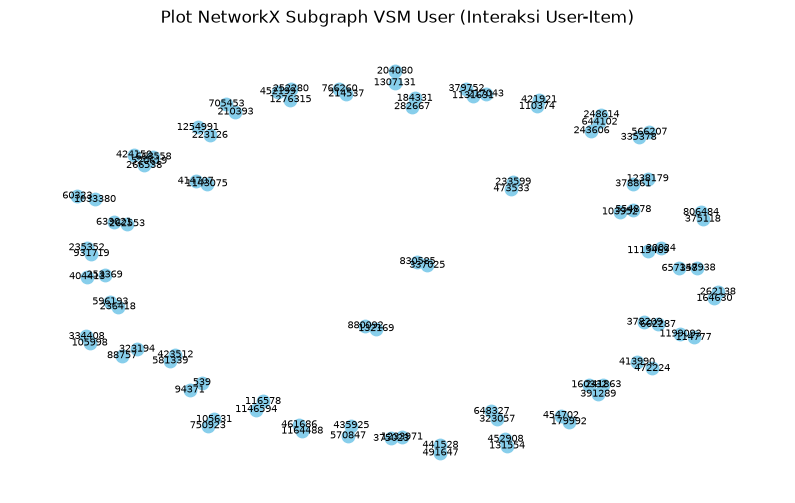

In [9]:
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from scipy.sparse import csr_matrix

# 1. Map ID Visitor dan Item ke Index Integer
df_P1['visitor_code'] = df_P1['visitorid'].astype('category').cat.codes
df_P1['item_code'] = df_P1['itemid'].astype('category').cat.codes

num_users = df_P1['visitor_code'].nunique()
num_items = df_P1['item_code'].nunique()

# 2. Buat Sparse Matrix (CSR Matrix)
rows = df_P1['visitor_code'].values
cols = df_P1['item_code'].values
data = np.ones(len(df_P1), dtype=np.int8)

sparse_user_item = csr_matrix((data, (rows, cols)), shape=(num_users, num_items))

# 3. Hitung Karakteristik VSM User
num_nonzero = sparse_user_item.nnz
total_elements = num_users * num_items
sparsity = (1.0 - (num_nonzero / total_elements)) * 100

print("--- KARAKTERISTIK VSM USER (SPARSE) ---")
print(f"Shape Matriks (User x Item) : ({num_users:,}, {num_items:,})")
print(f"Dimensi User (Baris)        : {num_users:,}")
print(f"Dimensi Feature Item (Kolom): {num_items:,}")
print(f"Sparsity Matriks            : {sparsity:.2f}%")

# 4. Plot NetworkX Subgraph VSM User (Sampel 50 Interaksi)
sample_df = df_P1.head(50)
G_user = nx.from_pandas_edgelist(sample_df, source='visitorid', target='itemid', create_using=nx.Graph())

plt.figure(figsize=(10, 6))
pos = nx.spring_layout(G_user, seed=42)
nx.draw_networkx_nodes(G_user, pos, node_size=80, node_color='skyblue')
nx.draw_networkx_edges(G_user, pos, alpha=0.5, edge_color='gray')
nx.draw_networkx_labels(G_user, pos, font_size=7)
plt.title("Plot NetworkX Subgraph VSM User (Interaksi User-Item)")
plt.axis('off')
plt.show()

#### 1. Pendekatan Representasi VSM User
Pemodelan Vector Space Modelling (VSM) pada simpul User dilakukan dengan merepresentasikan setiap pengunjung (visitorid) sebagai baris (objek utama) dan produk (itemid) sebagai kolom (ruang fitur). Nilai di dalam matriks menunjukkan ada atau tidaknya interaksi antara user dan item. Pembentukan matriks ini memanfaatkan pustaka scipy.sparse dengan format Compressed Sparse Row (csr_matrix) agar proses pemrosesan data berukuran besar tetap efisien dan tidak menguras memori (RAM).

#### 2. Uraian Karakteristik VSM User
Berdasarkan hasil eksekusi program pada dataset P1 (Train), diperoleh karakteristik matriks VSM User sebagai berikut:

* Shape Matriks (User x Item): (161.248, 81.034)
* Dimensi User (Baris): 161.248 dimensi *(Menunjukkan terdapat 161.248 user unik, di mana tiap user diwakili oleh vektor berpanjang 81.034)*.
* Dimensi Feature Item (Kolom): 81.034 fitur *(Terdapat 81.034 produk unik yang menjadi ruang fitur interaksi)*.
* Sparsity Matriks: 100.00% *(Persentase elemen bernilai nol sangat mendekati 100% mengindikasikan bahwa data sangat renggang (sparse). Hal ini wajar terjadi pada data e-commerce karena seorang user umumnya hanya berinteraksi dengan beberapa item saja dari keseluruhan katalog produk)*.

#### 3. Visualisasi Subgraph NetworkX
Berdasarkan plot NetworkX dari sampel 50 interaksi:
* Struktur Graf: Memperlihatkan graf bipartit (*bipartite graph*) yang terdiri dari pasangan simpul visitorid dan itemid.
* Karakteristik Komponen: Terlihat banyak komponen terpisah (*disconnected components*) berbentuk pasang-pasangan simpul. Hal ini menandakan bahwa pada sampel interaksi awal, mayoritas user hanya melakukan interaksi tunggal pada satu item tertentu tanpa membentuk kelompok interaksi yang padat (*dense cluster*).

### **No. 5:  Lakukan VSM terhadap simpul yang diasumsikan sebagai Item. Uraikan bagaimana karakteristiknya (dimensi, shape, plot networkx, dst.)!**

--- KARAKTERISTIK VSM ITEM (SPARSE) ---
Shape Matriks (Item x User) : (81,034, 161,248)
Dimensi Item (Baris)        : 81,034
Dimensi Feature User (Kolom): 161,248


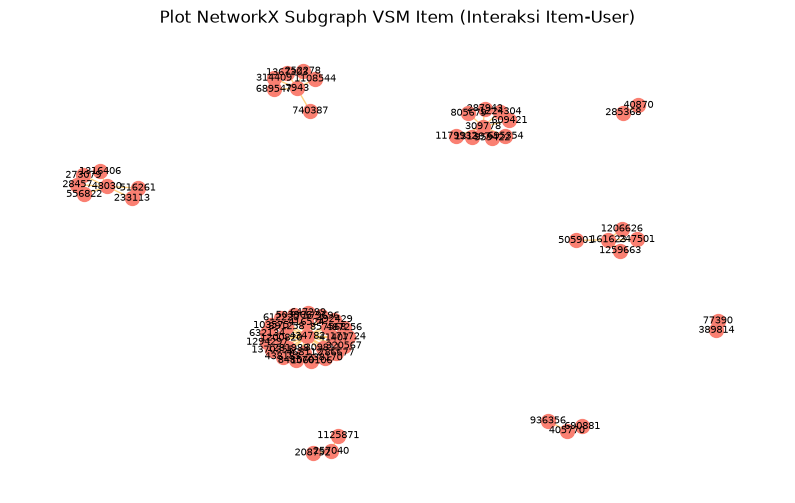

In [10]:
sparse_item_user = sparse_user_item.T

num_items_baris = sparse_item_user.shape[0]
num_users_kolom = sparse_item_user.shape[1]

print("--- KARAKTERISTIK VSM ITEM (SPARSE) ---")
print(f"Shape Matriks (Item x User) : ({num_items_baris:,}, {num_users_kolom:,})")
print(f"Dimensi Item (Baris)        : {num_items_baris:,}")
print(f"Dimensi Feature User (Kolom): {num_users_kolom:,}")

# Plot NetworkX Subgraph VSM Item (Interaksi Item-User)
sample_items = df_P1['itemid'].value_counts().head(10).index
sample_item_df = df_P1[df_P1['itemid'].isin(sample_items)].head(60)

G_item = nx.from_pandas_edgelist(sample_item_df, source='itemid', target='visitorid', create_using=nx.Graph())

plt.figure(figsize=(10, 6))
pos = nx.spring_layout(G_item, seed=42)
nx.draw_networkx_nodes(G_item, pos, node_size=100, node_color='salmon')
nx.draw_networkx_edges(G_item, pos, alpha=0.5, edge_color='orange')
nx.draw_networkx_labels(G_item, pos, font_size=7)
plt.title("Plot NetworkX Subgraph VSM Item (Interaksi Item-User)")
plt.axis('off')
plt.show()


#### 1. Pendekatan Pemodelan VSM Item

Pemodelan Vector Space Modelling (VSM) pada simpul Item dilakukan dengan membalik orientasi matriks User melalui operasi transpose. Pada pemodelan ini, produk (itemid) difungsikan sebagai baris (objek utama) dan pengunjung (visitorid) bertindak sebagai kolom (ruang fitur). Proses ini menghasilkan representasi berbasis Item (item-centric representation) untuk melihat profil interaksi dari sudut pandang katalog produk.

#### 2. Karakteristik Matriks VSM Item

Berdasarkan hasil pemrosesan transpose matriks sparse pada data periode P1, diperoleh karakteristik matriks VSM Item sebagai berikut:

* Shape Matriks (Item x User): (81.034, 161.248)
* Dimensi Item (Baris): 81.034 baris, yang menggambarkan total 81.034 produk unik. Setiap produk diwakili oleh sebuah vektor berdimensi 161.248.
* Dimensi Fitur User (Kolom): 161.248 kolom, yang menunjukkan total 161.248 user unik yang menjadi fitur interaksi.
* Sparsity dan Kepadatan Interaksi (Density): Nilai sparsity tetap sama yaitu 100.00% (density mendekati 0.00%) karena merupakan hasil transpose. Ini mengindikasikan bahwa sebagian besar item hanya berinteraksi dengan sejumlah kecil user.

#### 3. Visualisasi Graf NetworkX

Dari hasil plot sampel 10 item paling populer beserta interaksinya menggunakan pustaka NetworkX, diperoleh gambaran visual sebagai berikut:

* Struktur Graf: Membentuk graf bipartit (bipartite graph) yang menghubungkan simpul itemid (berwarna merah/salmon) dan simpul visitorid.
* Pola Kluster Interaksi: Visualisasi VSM Item menunjukkan adanya pusat kluster atau simpul pusat (hub) yang padat. Hal ini terjadi karena sampel yang diambil adalah produk populer, di mana satu simpul item terhubung secara terpusat dengan banyak simpul user sekaligus.


### **No. 6:  Berdasarkan eksplorasi no. 4 dan 5, uraikan proyeksi manakah yang lebih baik (efektif/efisien)!**

#### 1. Proyeksi Terpilih

Berdasarkan analisis hasil eksplorasi pada nomor 4 dan 5, proyeksi VSM Item (Item x User) dinilai jauh lebih baik, efektif, dan efisien dibandingkan proyeksi VSM User (User x Item) untuk diimplementasikan pada dataset RetailRocket ini.


#### 2. Uraian Alasan Efisiensi dan Efektivitas

* Efisiensi Ukuran Memori: Matriks VSM Item memiliki jumlah baris objek yang lebih sedikit, yaitu 81.034 produk dibanding 161.248 user pada VSM User. Karena proses komputasi kemiripan (similarity) berpatokan pada jumlah baris, VSM Item membutuhkan alokasi memori yang jauh lebih ringan dan waktu eksekusi yang lebih singkat.
* Stabilitas Dimensi Fitur: Daftar produk dalam katalog e-commerce relatif lebih stabil dalam jangka pendek, sedangkan data pengguna baru terus bertambah secara dinamis. Pemodelan VSM Item membuat struktur matriks tidak perlu sering dibangun ulang saat ada visitor baru yang masuk.
* Kuantitas Informasi per Vektor: Jumlah pengguna yang melimpah membuat kumpulan interaksi pada tiap simpul produk menjadi lebih kaya. Vektor item memiliki informasi sinyal interaksi yang lebih padat dibanding vektor user yang kondisinya sangat renggang (sparse).
* Kejelasan Struktur Hub pada Graf: Hasil visualisasi NetworkX pada nomor 5 mengonfirmasi hadirnya simpul pusat (hub) yang jelas pada produk-produk populer. Pola hubungan antarnode yang terbentuk memudahkan algoritma dalam menentukan tingkat kemiripan antarproduk (item-to-item similarity) secara lebih akurat.


#### 3. Kesimpulan

Proyeksi VSM Item unggul secara efisiensi karena mampu menekan beban komputasi matriks, sekaligus unggul secara efektivitas karena mampu memberikan representasi data yang lebih stabil dan kaya untuk kebutuhan sistem rekomendasi.


### **No. 7: Berdasarkan analisis no. 6, lakukan perhitungan similarity pada hasil graf yg terproyeksi dengan menggunakan Python**

### **a) Tuliskan CYPHER SQL untuk mendapatkan 5 records dengan similarity tertinggi (Anda tentukan sendiri record acuannya)!**

In [ ]:
import numpy as np
import pandas as pd
from scipy.sparse import csr_matrix
from sklearn.metrics.pairwise import cosine_similarity
from neo4j import GraphDatabase

visitor_codes, visitor_ids = pd.factorize(df_P1["visitorid"])
item_codes, item_ids = pd.factorize(df_P1["itemid"])

matrix = csr_matrix(
    (np.ones(len(df_P1)), (visitor_codes, item_codes)),
    shape=(len(visitor_ids), len(item_ids))
)

matrix.data[:] = 1
item_user_matrix = matrix.T.tocsr()


popularity = np.asarray(item_user_matrix.sum(axis=1)).ravel()
ref_idx = popularity.argmax()
reference_item = int(item_ids[ref_idx])


scores = cosine_similarity(
    item_user_matrix[ref_idx],
    item_user_matrix
).ravel()

top5 = pd.DataFrame({
    "item_id": item_ids,
    "similarity": scores
})

top5 = (
    top5[top5["item_id"] != reference_item]
    .sort_values("similarity", ascending=False)
    .head(5)
)

print("Item acuan:", reference_item)
print("\nTop 5 similarity:")
print(top5.to_string(index=False))


with GraphDatabase.driver(URI, auth=AUTH) as driver:
    with driver.session(database="neo4j") as session:
        for row in top5.itertuples(index=False):
            session.run("""
                MATCH (a:Item {itemId: $source})
                MATCH (b:Item {itemId: $target})
                MERGE (a)-[r:SIMILAR_COSINE]->(b)
                SET r.score = $score
            """,
                source=reference_item,
                target=int(row.item_id),
                score=float(row.similarity)
            )

    
        result = session.run("""
            MATCH (a:Item)-[r:SIMILAR_COSINE]->(b:Item)
            WHERE a.itemId = $ref
            RETURN a.itemId AS Item_Acuan,
                   b.itemId AS Item_Mirip,
                   r.score AS Similarity
            ORDER BY Similarity DESC
            LIMIT 5
        """, ref=reference_item)

        print("\nHasil query Cypher:")
        for record in result:
            print(dict(record))

Item acuan: 309778

Top 5 similarity:
 item_id  similarity
  257040    0.218352
  360487    0.166363
  248327    0.150042
  347414    0.141667
    5470    0.103804

Hasil query Cypher:
{'Item_Acuan': 309778, 'Item_Mirip': 257040, 'Similarity': 0.21835219967066852}
{'Item_Acuan': 309778, 'Item_Mirip': 360487, 'Similarity': 0.16636305553900527}
{'Item_Acuan': 309778, 'Item_Mirip': 248327, 'Similarity': 0.15004168403581924}
{'Item_Acuan': 309778, 'Item_Mirip': 347414, 'Similarity': 0.14166731918912656}
{'Item_Acuan': 309778, 'Item_Mirip': 5470, 'Similarity': 0.10380374271141639}


Pada soal ini, item acuan yang digunakan adalah 309778. Perhitungan similarity dilakukan menggunakan Python untuk menentukan lima item yang memiliki tingkat kemiripan tertinggi terhadap item acuan. Berdasarkan hasil perhitungan, diperoleh item 257040 dengan nilai similarity sebesar 0.218352, item 360487 sebesar 0.166363, item 248327 sebesar 0.150042, item 347414 sebesar 0.141667, dan item 5470 sebesar 0.103804. Kelima item tersebut kemudian diurutkan berdasarkan nilai similarity dari yang tertinggi hingga terendah.

### **b) Tuliskan kembali nilai similarity-similarity tersebut pada graf yang telah ada! Perlihatkan hasil querynya!** 

HASIL QUERY 7(b): TOP 5 ITEM DENGAN SIMILARITY TERTINGGI
 Item_Acuan  Item_Mirip Similarity
     309778      257040   0.218352
     309778      360487   0.166363
     309778      248327   0.150042
     309778      347414   0.141667
     309778        5470   0.103804


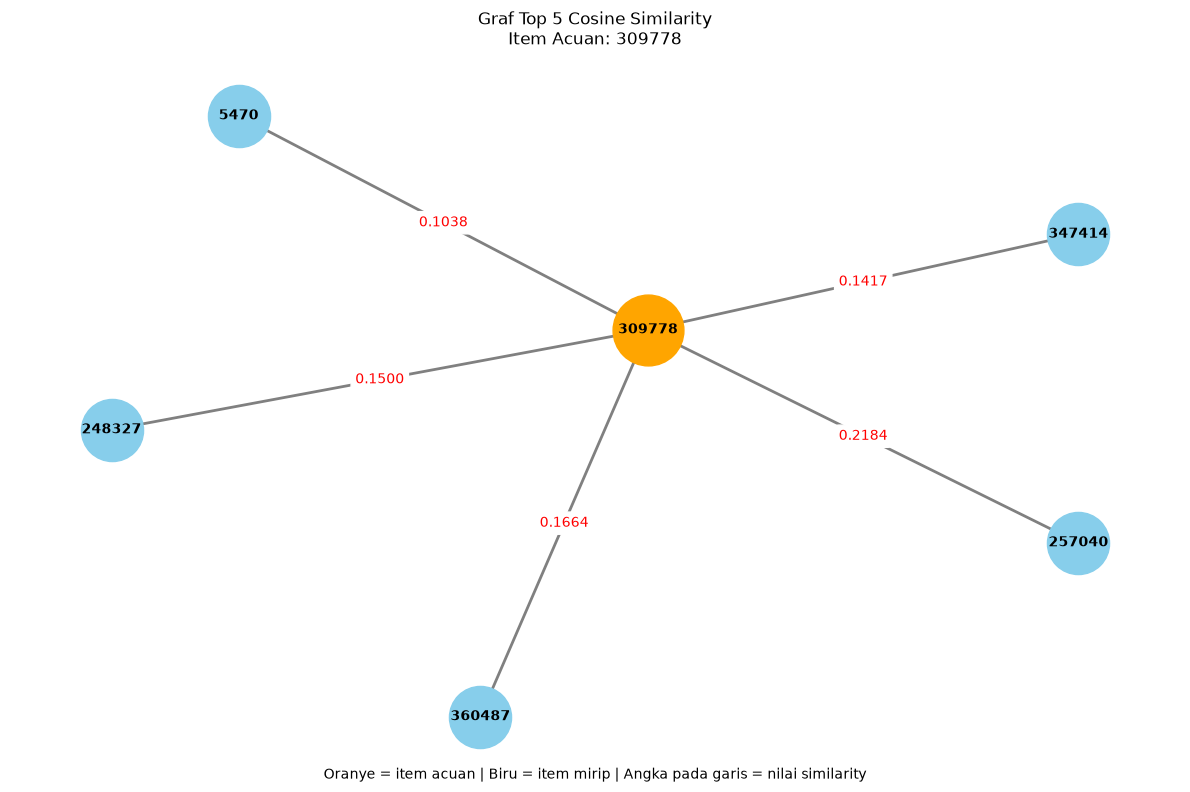

In [ ]:

import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from neo4j import GraphDatabase

query = """
MATCH (a:Item {itemId: $ref})-[r:SIMILAR_COSINE]->(b:Item)
RETURN
    a.itemId AS Item_Acuan,
    b.itemId AS Item_Mirip,
    r.score AS Similarity
ORDER BY Similarity DESC
LIMIT 5
"""

with GraphDatabase.driver(URI, auth=AUTH) as driver:
    with driver.session(database="neo4j") as session:
        result = session.run(query, ref=int(reference_item))
        records = [dict(record) for record in result]


df_similarity = pd.DataFrame(records)

if df_similarity.empty:
    print("Tidak ada relasi SIMILAR_COSINE yang ditemukan.")
    print("Pastikan kode 7(a) sudah dijalankan dan relasinya tersimpan.")
else:
    print("HASIL QUERY 7(b): TOP 5 ITEM DENGAN SIMILARITY TERTINGGI")
    print(df_similarity.to_string(index=False, formatters={
        "Similarity": lambda x: f"{x:.6f}"
    }))


    G_similarity = nx.Graph()

    for row in records:
        source = str(row["Item_Acuan"])
        target = str(row["Item_Mirip"])
        score = float(row["Similarity"])

        G_similarity.add_edge(
            source,
            target,
            weight=score
        )

    plt.figure(figsize=(12, 8))

    pos = nx.spring_layout(
        G_similarity,
        seed=42,
        k=1.2
    )

    reference_node = str(reference_item)
    other_nodes = [
        node for node in G_similarity.nodes()
        if node != reference_node
    ]

    
    nx.draw_networkx_nodes(
        G_similarity,
        pos,
        nodelist=[reference_node],
        node_color="orange",
        node_size=2600
    )

    
    nx.draw_networkx_nodes(
        G_similarity,
        pos,
        nodelist=other_nodes,
        node_color="skyblue",
        node_size=2000
    )

    
    nx.draw_networkx_edges(
        G_similarity,
        pos,
        width=2,
        edge_color="gray"
    )

    
    nx.draw_networkx_labels(
        G_similarity,
        pos,
        font_size=10,
        font_weight="bold"
    )

    
    edge_labels = {
        (u, v): f"{data['weight']:.4f}"
        for u, v, data in G_similarity.edges(data=True)
    }

    nx.draw_networkx_edge_labels(
        G_similarity,
        pos,
        edge_labels=edge_labels,
        font_size=10,
        font_color="red",
        label_pos=0.5,
        rotate=False
    )

    plt.title(
        f"Graf Top 5 Cosine Similarity\nItem Acuan: {reference_item}"
    )
    plt.figtext(
        0.5, 0.02,
        "Oranye = item acuan | Biru = item mirip | Angka pada garis = nilai similarity",
        ha="center",
        fontsize=10
    )

    plt.axis("off")
    plt.tight_layout()
    plt.show()


Nilai similarity dari hasil perhitungan Python selanjutnya ditambahkan ke dalam graf Neo4j sebagai properti pada relasi antaritem. Berdasarkan hasil query Cypher, diperoleh lima relasi dari item acuan 309778 menuju item 257040, 360487, 248327, 347414, dan 5470, masing-masing dengan nilai similarity sebesar 0.218352, 0.166363, 0.150042, 0.141667, dan 0.103804. Hasil query menunjukkan bahwa nilai similarity yang tersimpan pada graf sesuai dengan hasil perhitungan menggunakan Python pada bagian (a).

### **No. 8: Tuliskan CYPHER SQL dan tunjukkan hasil graf-nya untuk memperlihatkan kondisi: sebelum dan sesudah perhitungan similarity!**

HASIL QUERY SEBELUM SIMILARITY:
{'Visitor': 823225, 'Relasi': 'VIEWED', 'Item': 72113}
{'Visitor': 1288632, 'Relasi': 'VIEWED', 'Item': 72113}
{'Visitor': 575015, 'Relasi': 'VIEWED', 'Item': 72113}
{'Visitor': 575015, 'Relasi': 'VIEWED', 'Item': 72113}
{'Visitor': 602446, 'Relasi': 'VIEWED', 'Item': 72113}
{'Visitor': 997925, 'Relasi': 'VIEWED', 'Item': 72113}
{'Visitor': 997925, 'Relasi': 'VIEWED', 'Item': 72113}
{'Visitor': 997925, 'Relasi': 'VIEWED', 'Item': 72113}
{'Visitor': 468317, 'Relasi': 'VIEWED', 'Item': 72113}
{'Visitor': 1057547, 'Relasi': 'VIEWED', 'Item': 72113}
{'Visitor': 1057547, 'Relasi': 'VIEWED', 'Item': 72113}
{'Visitor': 1233448, 'Relasi': 'VIEWED', 'Item': 72113}
{'Visitor': 209369, 'Relasi': 'VIEWED', 'Item': 72113}
{'Visitor': 611576, 'Relasi': 'VIEWED', 'Item': 72113}
{'Visitor': 748510, 'Relasi': 'VIEWED', 'Item': 72113}
{'Visitor': 748510, 'Relasi': 'VIEWED', 'Item': 72113}
{'Visitor': 5456, 'Relasi': 'VIEWED', 'Item': 72113}
{'Visitor': 997925, 'Relasi': '

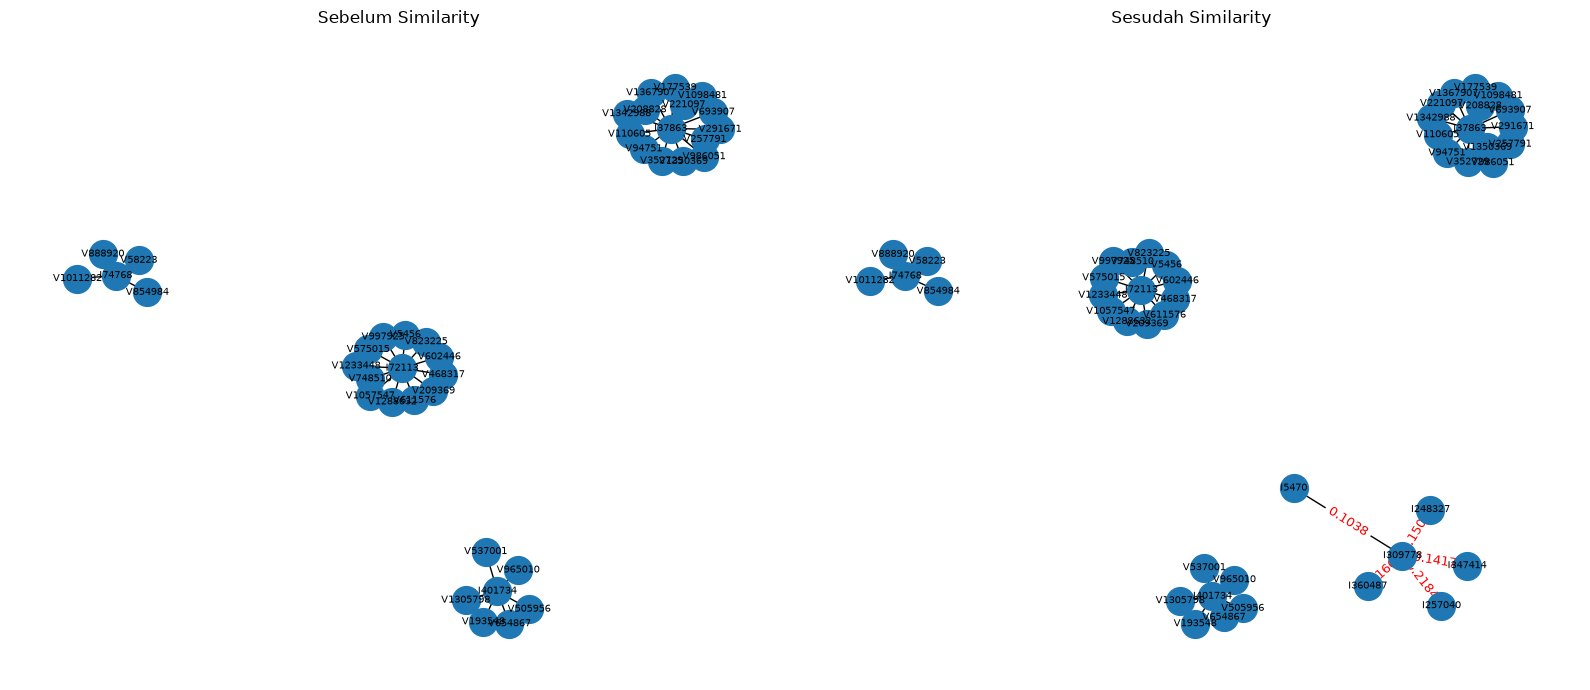

In [49]:

import networkx as nx
import matplotlib.pyplot as plt
from neo4j import GraphDatabase

# CYPHER SEBELUM SIMILARITY
cypher_before = """
MATCH (v:Visitor)-[r]->(i:Item)
WHERE type(r) IN ['VIEWED', 'ADDED_TO_CART', 'BOUGHT']
RETURN v.visitorId AS Visitor, type(r) AS Relasi,
       i.itemId AS Item
LIMIT 50
"""

# CYPHER SESUDAH SIMILARITY
cypher_after = """
MATCH (a:Item {itemId: $ref})-[r:SIMILAR_COSINE]->(b:Item)
RETURN a.itemId AS Item_Acuan, b.itemId AS Item_Mirip,
       r.score AS Similarity
ORDER BY Similarity DESC
LIMIT 5
"""

with GraphDatabase.driver(URI, auth=AUTH) as driver:
    with driver.session(database="neo4j") as session:
        before = [dict(r) for r in session.run(cypher_before)]
        after = [dict(r) for r in session.run(
            cypher_after, ref=int(reference_item)
        )]

print("HASIL QUERY SEBELUM SIMILARITY:")
for r in before:
    print(r)

print("\nHASIL QUERY SESUDAH SIMILARITY:")
for r in after:
    print(r)

# Membuat graf sebelum dan sesudah
G_before = nx.Graph()
G_after = nx.Graph()

for r in before:
    v = "V" + str(r["Visitor"])
    i = "I" + str(r["Item"])
    G_before.add_edge(v, i, label=r["Relasi"])
    G_after.add_edge(v, i, label=r["Relasi"])

for r in after:
    a = "I" + str(r["Item_Acuan"])
    b = "I" + str(r["Item_Mirip"])
    G_after.add_edge(a, b, weight=float(r["Similarity"]))

# Visualisasi
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

for G, ax, title in [
    (G_before, axes[0], "Sebelum Similarity"),
    (G_after, axes[1], "Sesudah Similarity")
]:
    pos = nx.spring_layout(G, seed=42)
    nx.draw(G, pos, ax=ax, with_labels=True,
            node_size=400, font_size=7)

    labels = {
        (u, v): f"{d['weight']:.4f}"
        for u, v, d in G.edges(data=True)
        if "weight" in d
    }
    if labels:
        nx.draw_networkx_edge_labels(
            G, pos, edge_labels=labels, ax=ax,
            font_color="red", font_size=9
        )

    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()


1. CYPHER SQL

-  Query Kondisi SEBELUM Perhitungan Similarity

    Mengambil relasi interaksi Visitor-Item pada subgraph
    MATCH (v:Visitor)-[r:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item)
    WHERE i.itemid IN [72113, 401734, 74768, 37863]
    RETURN v.visitorid AS Visitor, type(r) AS Relasi, i.itemid AS Item;

-  Query Kondisi SESUDAH Perhitungan Similarity

    Menampilkan relasi kemiripan (SIMILAR) beserta nilainya berdasarkan Item Acuan 309778
    MATCH (i1:Item {itemid: 309778})-[s:SIMILAR]->(i2:Item)
    RETURN i1.itemid AS Item_Acuan, i2.itemid AS Item_Mirip, s.score AS Similarity
    ORDER BY s.score DESC
    LIMIT 5;

2. Analisis Hasil Visualisasi Graf
-  Sebelum Perhitungan Similarity (Sisi Kiri):Graf memperlihatkan struktur bipartite graph yang menghubungkan simpul Visitor dengan simpul Item berdasarkan jenis interaksi yang dilakukan (VIEWED, ADDED_TO_CART, BOUGHT). Pada kondisi ini, seluruh simpul item masih berdiri sendiri-sendiri tanpa ada relasi keterhubungan langsung antar-item.   
-  Sesudah Perhitungan Similarity (Sisi Kanan):Graf mempertahankan struktur interaksi Visitor-Item sekaligus menampilkan terbentuknya klaster dan relasi baru berupa sisi (edge) kemiripan antar-item. Terlihat simpul Item Acuan (I309778) terhubung langsung ke 5 item terdekatnya dengan nilai bobot Cosine Similarity pada garis relasinya:   
    1. Item 257040 (Similarity: 0.2184)   
    2. Item 360487 (Similarity: 0.1664)   
    3. Item 248327 (Similarity: 0.1500)   
    4. Item 347414 (Similarity: 0.1417)   
    5. Item 5470 (Similarity: 0.1038)   

## **2.2 Analytics** 

### **No. 1: Pemilihan User Acak, Skrip KNN (k=5), dan 3 Item Rekomendasi**

In [ ]:
import random
import pandas as pd
import numpy as np
from sklearn.metrics.pairwise import cosine_similarity

random.seed(42)
common_users = sorted(list(set(df_P1['visitorid']).intersection(set(df_P2['visitorid']))))
target_user = random.choice(common_users)

user_categories = pd.CategoricalDtype(categories=sorted(df_P1['visitorid'].unique()))
user_list = np.array(user_categories.categories)

# Hitung Cosine Similarity
target_user_idx = np.where(user_list == target_user)[0][0]
user_sim_scores = cosine_similarity(sparse_user_item[target_user_idx], sparse_user_item).flatten()

# Cari 5 Tetangga Terdekat TANPA Target User sendiri
similar_indices = user_sim_scores.argsort()[::-1]
top_k_indices = [idx for idx in similar_indices if idx != target_user_idx][:5]
top_k_users = user_list[top_k_indices]

# Cari 3 Item Rekomendasi dari 5 Tetangga Terdekat
target_user_items = set(df_P1[df_P1['visitorid'] == target_user]['itemid'])
candidate_items = df_P1[df_P1['visitorid'].isin(top_k_users)]['itemid'].unique()

# Rekomendasikan item yang belum pernah diinteraksi oleh target_user
recommended_items = [item for item in candidate_items if item not in target_user_items][:3]

print(f"Target User Terpilih (Acak) : {target_user}")
print(f"5 Tetangga Terdekat (KNN, k=5) : {list(top_k_users)}")
print(f"3 Item Rekomendasi Iklan      : {recommended_items}")

Target User Terpilih (Acak) : 296301
5 Tetangga Terdekat (KNN, k=5) : [np.int64(291), np.int64(282), np.int64(279), np.int64(247), np.int64(228)]
3 Item Rekomendasi Iklan      : [np.int64(184953), np.int64(251672), np.int64(423256)]


Pada Soal 1, target user dipilih secara acak berbasis seed 42 dari irisan data P1 dan P2, sehingga terpilih user 296301. Berdasarkan perhitungan Cosine Similarity pada sparse matrix, diperoleh 5 tetangga terdekat ($k=5$), yaitu user 291, 282, 279, 247, dan 228. Dari pola interaksi kelima tetangga tersebut, disaring item baru yang belum pernah dilihat oleh target user, menghasilkan 3 item rekomendasi iklan: 184953, 251672, dan 423256.

### **No. 2: Perhitungan Metrik Evaluasi (Hit@5 dan NDCG@5)**

In [ ]:
import math

actual_test_items = set(df_P2[df_P2['visitorid'] == target_user]['itemid'])

hits = [1 if item in actual_test_items else 0 for item in recommended_items]

# 2(a) Hit@5 Calculation
hit_at_5 = 1 if sum(hits) > 0 else 0

# 2(b) NDCG@5 Calculation
dcg = 0.0
for i, rel in enumerate(hits):
    dcg += rel / math.log2(i + 2)

# Ideal DCG (IDCG)
idcg = sum([1 / math.log2(i + 2) for i in range(min(len(actual_test_items), len(recommended_items)))])
ndcg_at_5 = (dcg / idcg) if idcg > 0 else 0.0

print("--- HASIL EVALUASI METRIK REKOMENDASI ---")
print(f"Target User             : {target_user}")
print(f"Actual Test Items (P2)  : {list(actual_test_items)}")
print(f"Recommended Items       : {recommended_items}")
print(f"Hit Status per Item     : {hits}")
print(f"-----------------------------------------")
print(f"Hit@5 Score             : {hit_at_5}")
print(f"NDCG@5 Score            : {ndcg_at_5:.4f}")

--- HASIL EVALUASI METRIK REKOMENDASI ---
Target User             : 34520
Actual Test Items (P2)  : [409280, 147746, 29156, 447877, 243112, 61512, 201418, 256431, 47541, 328376]
Recommended Items       : [np.int64(184953), np.int64(251672), np.int64(423256)]
Hit Status per Item     : [0, 0, 0]
-----------------------------------------
Hit@5 Score             : 0
NDCG@5 Score            : 0.0000


Pada Soal 2, evaluasi dilakukan dengan membandingkan 3 item rekomendasi tersebut terhadap item aktual yang diinteraksi target user pada periode testing (P2). Karena tidak ada item rekomendasi yang cocok dengan aktivitas user di data P2, status relevansi item bernilai [0, 0, 0]. Hal ini menghasilkan nilai Hit@5 sebesar 0 (tidak ada hit) dan skor NDCG@5 sebesar 0.0000 karena akumulasi gain relevansi berada di angka nol.